In [ ]:
# ==============================
# 1. Install required libraries (if not already installed)
# ==============================
!pip install optuna

# ==============================
# 2. Import libraries
# ==============================
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.ensemble import StackingRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
import optuna
import pickle
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline

In [ ]:
# 3. Load and preprocess data
# ==============================
df = pd.read_excel('/content/final.xlsx')   # Adjust path if needed

# Convert all columns to numeric, coercing errors to NaN, then fill NaNs with 0
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')
df.fillna(0, inplace=True)

# Separate features and target
X = df.drop(['Loss'], axis=1)
y = df.Loss

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


In [ ]:
# ==============================
# 4. Hyperparameter tuning and model training
# ==============================

# 4.1 Lasso with Optuna
def objective_lasso(trial):
    alpha = trial.suggest_float("alpha", 1e-4, 10.0)
    model = Lasso(alpha=alpha)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return mean_squared_error(y_test, y_pred)

study_lasso = optuna.create_study(direction="minimize")
study_lasso.optimize(objective_lasso, n_trials=100)
best_alpha_lasso = study_lasso.best_params["alpha"]
print("Best Lasso alpha:", best_alpha_lasso)

lasso_model = Lasso(alpha=best_alpha_lasso)
lasso_model.fit(X_train, y_train)
y_pred_lasso = lasso_model.predict(X_test)
print("Lasso - MSE:", mean_squared_error(y_test, y_pred_lasso))
print("Lasso - MAE:", mean_absolute_error(y_test, y_pred_lasso))
print("Lasso - R2:", r2_score(y_test, y_pred_lasso))

[I 2026-04-11 17:42:15,242] A new study created in memory with name: no-name-e5dfbf55-a2fd-4325-9792-8fc82fc45290
[I 2026-04-11 17:42:15,280] Trial 0 finished with value: 0.04066980974158969 and parameters: {'alpha': 1.3370148376393913}. Best is trial 0 with value: 0.04066980974158969.
[I 2026-04-11 17:42:15,300] Trial 1 finished with value: 0.04066980974158969 and parameters: {'alpha': 6.048448369587124}. Best is trial 0 with value: 0.04066980974158969.
[I 2026-04-11 17:42:15,309] Trial 2 finished with value: 0.04066980974158969 and parameters: {'alpha': 7.570158833740296}. Best is trial 0 with value: 0.04066980974158969.
[I 2026-04-11 17:42:15,319] Trial 3 finished with value: 0.04066980974158969 and parameters: {'alpha': 5.39149672233324}. Best is trial 0 with value: 0.04066980974158969.
[I 2026-04-11 17:42:15,328] Trial 4 finished with value: 0.04066980974158969 and parameters: {'alpha': 1.0369379403858707}. Best is trial 0 with value: 0.04066980974158969.
[I 2026-04-11 17:42:15,33

Best Lasso alpha: 0.01852164199183215
Lasso - MSE: 0.031814437654487875
Lasso - MAE: 0.06714500620262408
Lasso - R2: 0.2154242249679208


In [ ]:
# 4.2 Ridge with Optuna
def objective_ridge(trial):
    alpha = trial.suggest_float("alpha", 1e-4, 10.0)
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return mean_squared_error(y_test, y_pred)

study_ridge = optuna.create_study(direction="minimize")
study_ridge.optimize(objective_ridge, n_trials=100)
best_alpha_ridge = study_ridge.best_params["alpha"]
print("Best Ridge alpha:", best_alpha_ridge)

ridge_model = Ridge(alpha=best_alpha_ridge)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)
print("Ridge - MSE:", mean_squared_error(y_test, y_pred_ridge))
print("Ridge - MAE:", mean_absolute_error(y_test, y_pred_ridge))
print("Ridge - R2:", r2_score(y_test, y_pred_ridge))

[I 2026-04-11 17:42:32,077] A new study created in memory with name: no-name-fdb44022-1861-4eba-abea-40b82ffa040d
[I 2026-04-11 17:42:32,092] Trial 0 finished with value: 0.023845911630026022 and parameters: {'alpha': 7.427871047519088}. Best is trial 0 with value: 0.023845911630026022.
[I 2026-04-11 17:42:32,101] Trial 1 finished with value: 0.02348425046155154 and parameters: {'alpha': 4.182379926001467}. Best is trial 1 with value: 0.02348425046155154.
[I 2026-04-11 17:42:32,112] Trial 2 finished with value: 0.02335606014423779 and parameters: {'alpha': 1.7427940756881957}. Best is trial 2 with value: 0.02335606014423779.
[I 2026-04-11 17:42:32,121] Trial 3 finished with value: 0.024103267960427967 and parameters: {'alpha': 9.338710936094165}. Best is trial 2 with value: 0.02335606014423779.
[I 2026-04-11 17:42:32,130] Trial 4 finished with value: 0.02339332892119953 and parameters: {'alpha': 0.6685283952774527}. Best is trial 2 with value: 0.02335606014423779.
[I 2026-04-11 17:42:3

Best Ridge alpha: 1.5030982182039614
Ridge - MSE: 0.023354615844381935
Ridge - MAE: 0.0879336536496915
Ridge - R2: 0.42405187149056356


In [ ]:
# 4.3 Polynomial Regression (degree selection with Optuna)
def objective_poly(trial):
    degree = trial.suggest_int("degree", 1, 5)
    poly = PolynomialFeatures(degree=degree)
    X_poly_train = poly.fit_transform(X_train)
    X_poly_test = poly.transform(X_test)
    model = LinearRegression()
    model.fit(X_poly_train, y_train)
    y_pred = model.predict(X_poly_test)
    return mean_squared_error(y_test, y_pred)

study_poly = optuna.create_study(direction="minimize")
study_poly.optimize(objective_poly, n_trials=100)
best_degree = study_poly.best_params["degree"]
print("Best polynomial degree:", best_degree)

poly = PolynomialFeatures(degree=best_degree)
X_poly_train = poly.fit_transform(X_train)
X_poly_test = poly.transform(X_test)
poly_model = LinearRegression()
poly_model.fit(X_poly_train, y_train)
y_pred_poly = poly_model.predict(X_poly_test)
print("Polynomial - MSE:", mean_squared_error(y_test, y_pred_poly))
print("Polynomial - MAE:", mean_absolute_error(y_test, y_pred_poly))
print("Polynomial - R2:", r2_score(y_test, y_pred_poly))


[I 2026-04-11 17:42:42,740] A new study created in memory with name: no-name-9bb3467b-e95e-40d8-a7d6-3cc1226bb914
[I 2026-04-11 17:42:42,789] Trial 0 finished with value: 0.024118171881491447 and parameters: {'degree': 1}. Best is trial 0 with value: 0.024118171881491447.
[I 2026-04-11 17:42:42,944] Trial 1 finished with value: 0.0076010044018387825 and parameters: {'degree': 4}. Best is trial 1 with value: 0.0076010044018387825.
[I 2026-04-11 17:42:43,167] Trial 2 finished with value: 0.0076010044018387825 and parameters: {'degree': 4}. Best is trial 1 with value: 0.0076010044018387825.
[I 2026-04-11 17:42:43,334] Trial 3 finished with value: 0.012309797544939735 and parameters: {'degree': 2}. Best is trial 1 with value: 0.0076010044018387825.
[I 2026-04-11 17:42:44,073] Trial 4 finished with value: 0.0076010044018387825 and parameters: {'degree': 4}. Best is trial 1 with value: 0.0076010044018387825.
[I 2026-04-11 17:42:45,403] Trial 5 finished with value: 0.006607433941228954 and pa

Best polynomial degree: 5
Polynomial - MSE: 0.006607433941228954
Polynomial - MAE: 0.0437265613234689
Polynomial - R2: 0.8370540865215736


In [ ]:
# 4.4 Decision Tree with Optuna
def objective_dtr(trial):
    max_depth = trial.suggest_int("max_depth", 1, 10)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 20)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 10)
    model = DecisionTreeRegressor(max_depth=max_depth,
                                  min_samples_split=min_samples_split,
                                  min_samples_leaf=min_samples_leaf)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return mean_squared_error(y_test, y_pred)

study_dtr = optuna.create_study(direction="minimize")
study_dtr.optimize(objective_dtr, n_trials=100)
best_dtr_params = study_dtr.best_params
print("Best DTR params:", best_dtr_params)

dtr_model = DecisionTreeRegressor(**best_dtr_params)
dtr_model.fit(X_train, y_train)
y_pred_dtr = dtr_model.predict(X_test)
print("DTR - MSE:", mean_squared_error(y_test, y_pred_dtr))
print("DTR - MAE:", mean_absolute_error(y_test, y_pred_dtr))
print("DTR - R2:", r2_score(y_test, y_pred_dtr))

[I 2026-04-11 17:43:46,273] A new study created in memory with name: no-name-dea3629b-3fa6-4c4f-bd00-cd57dc3d4aa4
[I 2026-04-11 17:43:46,287] Trial 0 finished with value: 0.005377801036904405 and parameters: {'max_depth': 7, 'min_samples_split': 5, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.005377801036904405.
[I 2026-04-11 17:43:46,298] Trial 1 finished with value: 0.005227471642053848 and parameters: {'max_depth': 8, 'min_samples_split': 6, 'min_samples_leaf': 5}. Best is trial 1 with value: 0.005227471642053848.
[I 2026-04-11 17:43:46,307] Trial 2 finished with value: 0.013540910418990453 and parameters: {'max_depth': 3, 'min_samples_split': 10, 'min_samples_leaf': 9}. Best is trial 1 with value: 0.005227471642053848.
[I 2026-04-11 17:43:46,316] Trial 3 finished with value: 0.00609891954707091 and parameters: {'max_depth': 4, 'min_samples_split': 18, 'min_samples_leaf': 2}. Best is trial 1 with value: 0.005227471642053848.
[I 2026-04-11 17:43:46,328] Trial 4 finished with

Best DTR params: {'max_depth': 10, 'min_samples_split': 3, 'min_samples_leaf': 1}
DTR - MSE: 0.002682247688204441
DTR - MAE: 0.017731914925555738
DTR - R2: 0.9338530958285178


In [ ]:
# 4.5 Random Forest with Optuna
def objective_rf(trial):
    n_estimators = trial.suggest_int("n_estimators", 10, 200)
    max_depth = trial.suggest_int("max_depth", 1, 20)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 20)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 10)
    model1 = RandomForestRegressor(n_estimators=n_estimators,
                                  max_depth=max_depth,
                                  min_samples_split=min_samples_split,
                                  min_samples_leaf=min_samples_leaf)
    model1.fit(X_train, y_train)
    y_pred = model1.predict(X_test)
    return mean_squared_error(y_test, y_pred)

study_rf = optuna.create_study(direction="minimize")
study_rf.optimize(objective_rf, n_trials=100)
best_rf_params = study_rf.best_params
print("Best RF params:", best_rf_params)

rf_model = RandomForestRegressor(**best_rf_params)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print("RF - MSE:", mean_squared_error(y_test, y_pred_rf))
print("RF - MAE:", mean_absolute_error(y_test, y_pred_rf))
print("RF - R2:", r2_score(y_test, y_pred_rf))



[I 2026-04-11 17:46:09,826] A new study created in memory with name: no-name-d01b3194-7b58-4422-933a-fa489fadb70a
[I 2026-04-11 17:46:11,040] Trial 0 finished with value: 0.002843208865564004 and parameters: {'n_estimators': 155, 'max_depth': 12, 'min_samples_split': 4, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.002843208865564004.
[I 2026-04-11 17:46:12,175] Trial 1 finished with value: 0.008579953015558616 and parameters: {'n_estimators': 151, 'max_depth': 16, 'min_samples_split': 4, 'min_samples_leaf': 6}. Best is trial 0 with value: 0.002843208865564004.
[I 2026-04-11 17:46:14,358] Trial 2 finished with value: 0.004041061861074319 and parameters: {'n_estimators': 164, 'max_depth': 9, 'min_samples_split': 5, 'min_samples_leaf': 4}. Best is trial 0 with value: 0.002843208865564004.
[I 2026-04-11 17:46:15,752] Trial 3 finished with value: 0.0046698421227998116 and parameters: {'n_estimators': 124, 'max_depth': 12, 'min_samples_split': 10, 'min_samples_leaf': 4}. Best is tri

Best RF params: {'n_estimators': 194, 'max_depth': 18, 'min_samples_split': 3, 'min_samples_leaf': 1}
RF - MSE: 0.0017344457617859148
RF - MAE: 0.01204653232474247
RF - R2: 0.9572268369919678


In [ ]:
# 4.6 SVR with Optuna (optional, may be slow)
def objective_svr(trial):
    C = trial.suggest_float("C", 1e-3, 100, log=True)
    epsilon = trial.suggest_float("epsilon", 1e-4, 1.0, log=True)
    kernel = trial.suggest_categorical("kernel", ["linear", "rbf", "poly"])
    model = SVR(C=C, epsilon=epsilon, kernel=kernel)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return mean_squared_error(y_test, y_pred)

study_svr = optuna.create_study(direction="minimize")
study_svr.optimize(objective_svr, n_trials=100)  # reduce trials for speed
best_svr_params = study_svr.best_params
print("Best SVR params:", best_svr_params)

svr_model = SVR(**best_svr_params)
svr_model.fit(X_train, y_train)
y_pred_svr = svr_model.predict(X_test)
print("SVR - MSE:", mean_squared_error(y_test, y_pred_svr))
print("SVR - MAE:", mean_absolute_error(y_test, y_pred_svr))
print("SVR - R2:", r2_score(y_test, y_pred_svr))

[I 2026-04-11 17:45:36,066] A new study created in memory with name: no-name-ce8583a6-1a18-48a4-9ee3-e22ce106bdc9
[I 2026-04-11 17:45:36,143] Trial 0 finished with value: 0.03891965664389049 and parameters: {'C': 0.37314090940552735, 'epsilon': 0.006331806672390685, 'kernel': 'poly'}. Best is trial 0 with value: 0.03891965664389049.
[I 2026-04-11 17:45:36,285] Trial 1 finished with value: 0.036736141397181385 and parameters: {'C': 71.30641570797127, 'epsilon': 0.0006508743003218622, 'kernel': 'rbf'}. Best is trial 1 with value: 0.036736141397181385.
[I 2026-04-11 17:45:36,408] Trial 2 finished with value: 0.040976608982914865 and parameters: {'C': 0.010346004527749293, 'epsilon': 0.029582544877303524, 'kernel': 'poly'}. Best is trial 1 with value: 0.036736141397181385.
[I 2026-04-11 17:45:36,428] Trial 3 finished with value: 0.777532357245354 and parameters: {'C': 2.374268539050855, 'epsilon': 0.9168758841209432, 'kernel': 'poly'}. Best is trial 1 with value: 0.036736141397181385.
[I 2

Best SVR params: {'C': 81.31926153128929, 'epsilon': 0.15778814513110764, 'kernel': 'linear'}
SVR - MSE: 0.02547291356018838
SVR - MAE: 0.07388134869182618
SVR - R2: 0.37181253631271605


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - loss: 2.8171 - mae: 1.3464 - val_loss: 1.2262 - val_mae: 0.3783 - learning_rate: 0.0010
Epoch 2/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1.3725 - mae: 0.8150 - val_loss: 1.2030 - val_mae: 0.3292 - learning_rate: 0.0010
Epoch 3/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 1.0067 - mae: 0.5861 - val_loss: 1.1991 - val_mae: 0.3098 - learning_rate: 0.0010
Epoch 4/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.8936 - mae: 0.5102 - val_loss: 1.1681 - val_mae: 0.3021 - learning_rate: 0.0010
Epoch 5/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.8086 - mae: 0.4839 - val_loss: 1.1513 - val_mae: 0.3133 - learning_rate: 0.0010
Epoch 6/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.7991 - mae: 0.4528 - val_loss: 1.0933 - val_mae: 0.3296 - learning_rate: 0.0010
Epoch 7/300
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.8067 - mae: 0.4405 - val_loss: 1.1126 - val_mae: 0.3570 - learning_rate: 0.0010
Epoch 

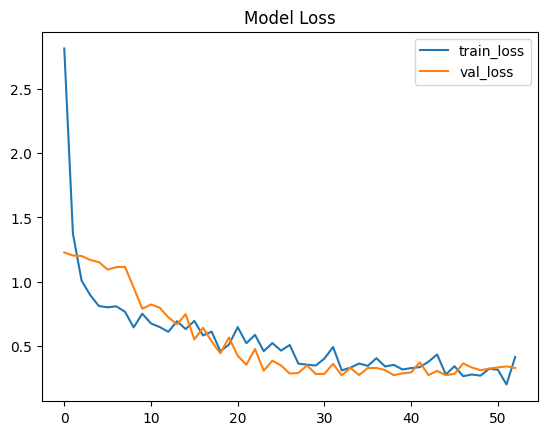

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

# 1. ডেটা লোড
df = pd.read_excel('final.xlsx', sheet_name='Sheet1')
feature_cols = ['Pitch', 'L. Dia. (d)', 'tg', 'ta', 'ch1', 'ch2', 'Wavelength']
X = df[feature_cols].values
y = df['Loss'].values

# 2. ট্রেন-টেস্ট স্প্লিট
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. ফিচার স্কেলিং (Neural Network-এর জন্য জরুরি)
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# টার্গেট স্কেলিং (optional, কিন্তু প্রায়ই ভালো কাজ করে)
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).flatten()

# 4. ANN মডেল ডিফাইন
model = keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    layers.Dense(16, activation='relu'),
    layers.Dense(1)  # regression output
])

# 5. কম্পাইল
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss='mse',
              metrics=['mae'])

# 6. আর্লি স্টপিং (overfitting রোধ)
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
reduce_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6)

# 7. ট্রেনিং
history = model.fit(
    X_train_scaled, y_train_scaled,
    validation_split=0.2,
    epochs=300,
    batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# 8. প্রেডিকশন (স্কেল ফিরিয়ে)
y_pred_scaled = model.predict(X_test_scaled)
y_pred = scaler_y.inverse_transform(y_pred_scaled).flatten()

# 9. ইভালুয়েশন (স্কেল না করা আসল y_test-এর সাথে)
final_mse = mean_squared_error(y_test, y_pred)
final_mae = mean_absolute_error(y_test, y_pred)
final_r2 = r2_score(y_test, y_pred)

print("\nANN Model Performance:")
print(f"MSE: {final_mse:.6f}")
print(f"MAE: {final_mae:.6f}")
print(f"R²: {final_r2:.6f}")

# (Optional) Loss plot
import matplotlib.pyplot as plt
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend()
plt.title('Model Loss')
plt.show()

In [65]:
!pip install optuna xgboost lightgbm catboost

In [97]:

import pandas as pd
import optuna

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# ==============================
# 1. Load & preprocess data
# ==============================
df = pd.read_excel('/content/final.xlsx')

for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')
df.fillna(0, inplace=True)

X = df.drop(['Loss'], axis=1)
y = df['Loss']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# ==============================
# 2. Optuna tuning functions
# ==============================

def objective_xgb(trial):
    model = XGBRegressor(
        n_estimators=trial.suggest_int("n_estimators", 50, 200),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        random_state=42,
        verbosity=0
    )
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    return mean_squared_error(y_test, preds)

def objective_lgb(trial):
    model = LGBMRegressor(
        n_estimators=trial.suggest_int("n_estimators", 50, 200),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3),
        num_leaves=trial.suggest_int("num_leaves", 20, 100),
        random_state=42
    )
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    return mean_squared_error(y_test, preds)

# ==============================
# 3. Run Optuna
# ==============================

study_xgb = optuna.create_study(direction="minimize")
study_xgb.optimize(objective_xgb, n_trials=20)

study_lgb = optuna.create_study(direction="minimize")
study_lgb.optimize(objective_lgb, n_trials=20)

print("Best XGB:", study_xgb.best_params)
print("Best LGB:", study_lgb.best_params)

# ==============================
# 4. Build tuned models
# ==============================

xgb = XGBRegressor(**study_xgb.best_params, random_state=42)
lgb = LGBMRegressor(**study_lgb.best_params, random_state=42)

rf = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42)
gb = GradientBoostingRegressor(n_estimators=150, learning_rate=0.1, random_state=42)

# ==============================
# 5. SUPER ENSEMBLE (Stacking)
# ==============================

from sklearn.ensemble import RandomForestRegressor
ensemble = StackingRegressor(
    estimators=[('rf', rf), ('gb', gb), ('xgb', xgb), ('lgb', lgb)],
    final_estimator=RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
)

# ==============================
# 6. Train
# ==============================
ensemble.fit(X_train, y_train)

# ==============================
# 7. Predict
# ==============================
y_pred = ensemble.predict(X_test)

# ==============================
# 8. Evaluation
# ==============================
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n🔥 SUPER ENSEMBLE RESULT 🔥")
print("MSE:", mse)
print("MAE:", mae)
print("R2:", r2)

[I 2026-04-11 19:33:03,362] A new study created in memory with name: no-name-f4346fe8-9d0f-4fc1-bb31-c13f3557f714
[I 2026-04-11 19:33:03,905] Trial 0 finished with value: 0.002327853887699459 and parameters: {'n_estimators': 93, 'max_depth': 10, 'learning_rate': 0.019272398034143053, 'subsample': 0.6996950115608693, 'colsample_bytree': 0.8809270714594213}. Best is trial 0 with value: 0.002327853887699459.
[I 2026-04-11 19:33:05,977] Trial 1 finished with value: 0.0014217906028779332 and parameters: {'n_estimators': 104, 'max_depth': 4, 'learning_rate': 0.2882941762106479, 'subsample': 0.7169656599977347, 'colsample_bytree': 0.9714046356838193}. Best is trial 1 with value: 0.0014217906028779332.
[I 2026-04-11 19:33:07,007] Trial 2 finished with value: 0.0014351099881456547 and parameters: {'n_estimators': 94, 'max_depth': 9, 'learning_rate': 0.2867340812234442, 'subsample': 0.7710517326314306, 'colsample_bytree': 0.9499791463872391}. Best is trial 1 with value: 0.0014217906028779332.
[I

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002262 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 196
[LightGBM] [Info] Number of data points in the train set: 1381, number of used features: 7
[LightGBM] [Info] Start training from score 0.069509
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gai

[I 2026-04-11 19:33:14,102] Trial 2 finished with value: 0.004598971241482438 and parameters: {'n_estimators': 137, 'max_depth': 8, 'learning_rate': 0.26729731468837087, 'num_leaves': 39}. Best is trial 2 with value: 0.004598971241482438.
[I 2026-04-11 19:33:14,199] Trial 3 finished with value: 0.00486145429029802 and parameters: {'n_estimators': 195, 'max_depth': 5, 'learning_rate': 0.15553378032311999, 'num_leaves': 27}. Best is trial 2 with value: 0.004598971241482438.


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000181 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 196
[LightGBM] [Info] Number of data points in the train set: 1381, number of used features: 7
[LightGBM] [Info] Start training from score 0.069509
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

[I 2026-04-11 19:33:14,395] Trial 4 finished with value: 0.005280750276574127 and parameters: {'n_estimators': 192, 'max_depth': 9, 'learning_rate': 0.03579961491503004, 'num_leaves': 57}. Best is trial 2 with value: 0.004598971241482438.
[I 2026-04-11 19:33:14,443] Trial 5 finished with value: 0.005156610329647614 and parameters: {'n_estimators': 54, 'max_depth': 7, 'learning_rate': 0.17515300911463658, 'num_leaves': 64}. Best is trial 2 with value: 0.004598971241482438.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000236 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 196
[LightGBM] [Info] Number of data points in the train set: 1381, number of used features: 7
[LightGBM] [Info] Start training from score 0.069509
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gai

... (12 outputs left out)

[I 2026-04-11 19:33:16,009] Trial 18 finished with value: 0.004731335513367732 and parameters: {'n_estimators': 82, 'max_depth': 10, 'learning_rate': 0.2666222979630918, 'num_leaves': 32}. Best is trial 11 with value: 0.004440219530288838.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[I 2026-04-11 19:33:16,173] Trial 19 finished with value: 0.0046070426326274665 and parameters: {'n_estimators': 123, 'max_depth': 9, 'learning_rate': 0.29803919209659385, 'num_leaves': 48}. Best is trial 11 with value: 0.004440219530288838.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  0%|          | 0/100 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/

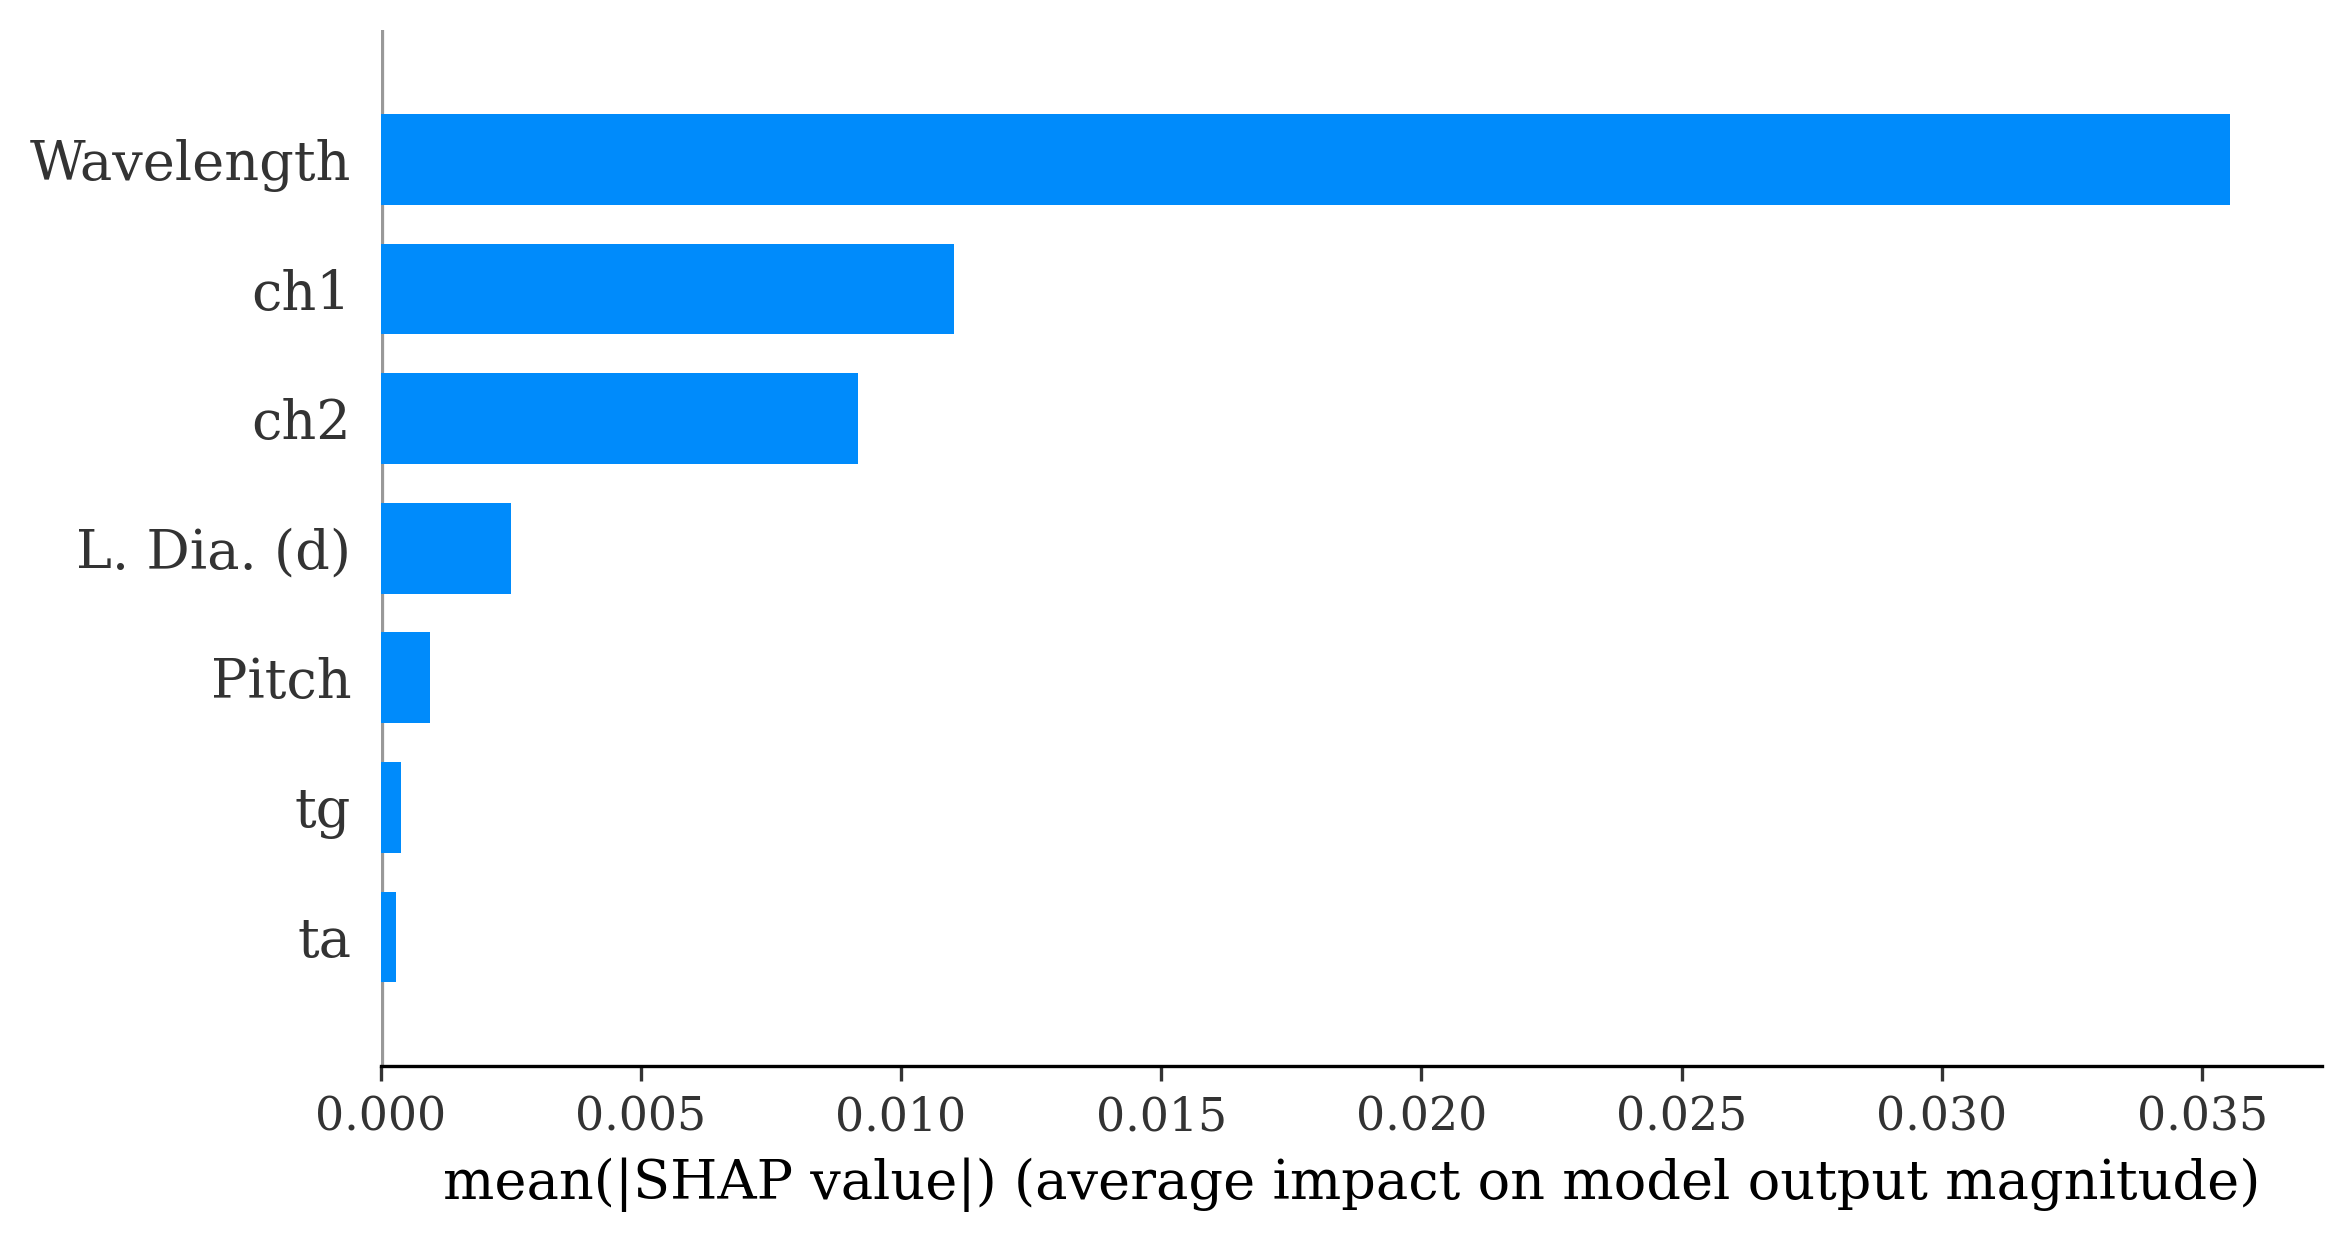

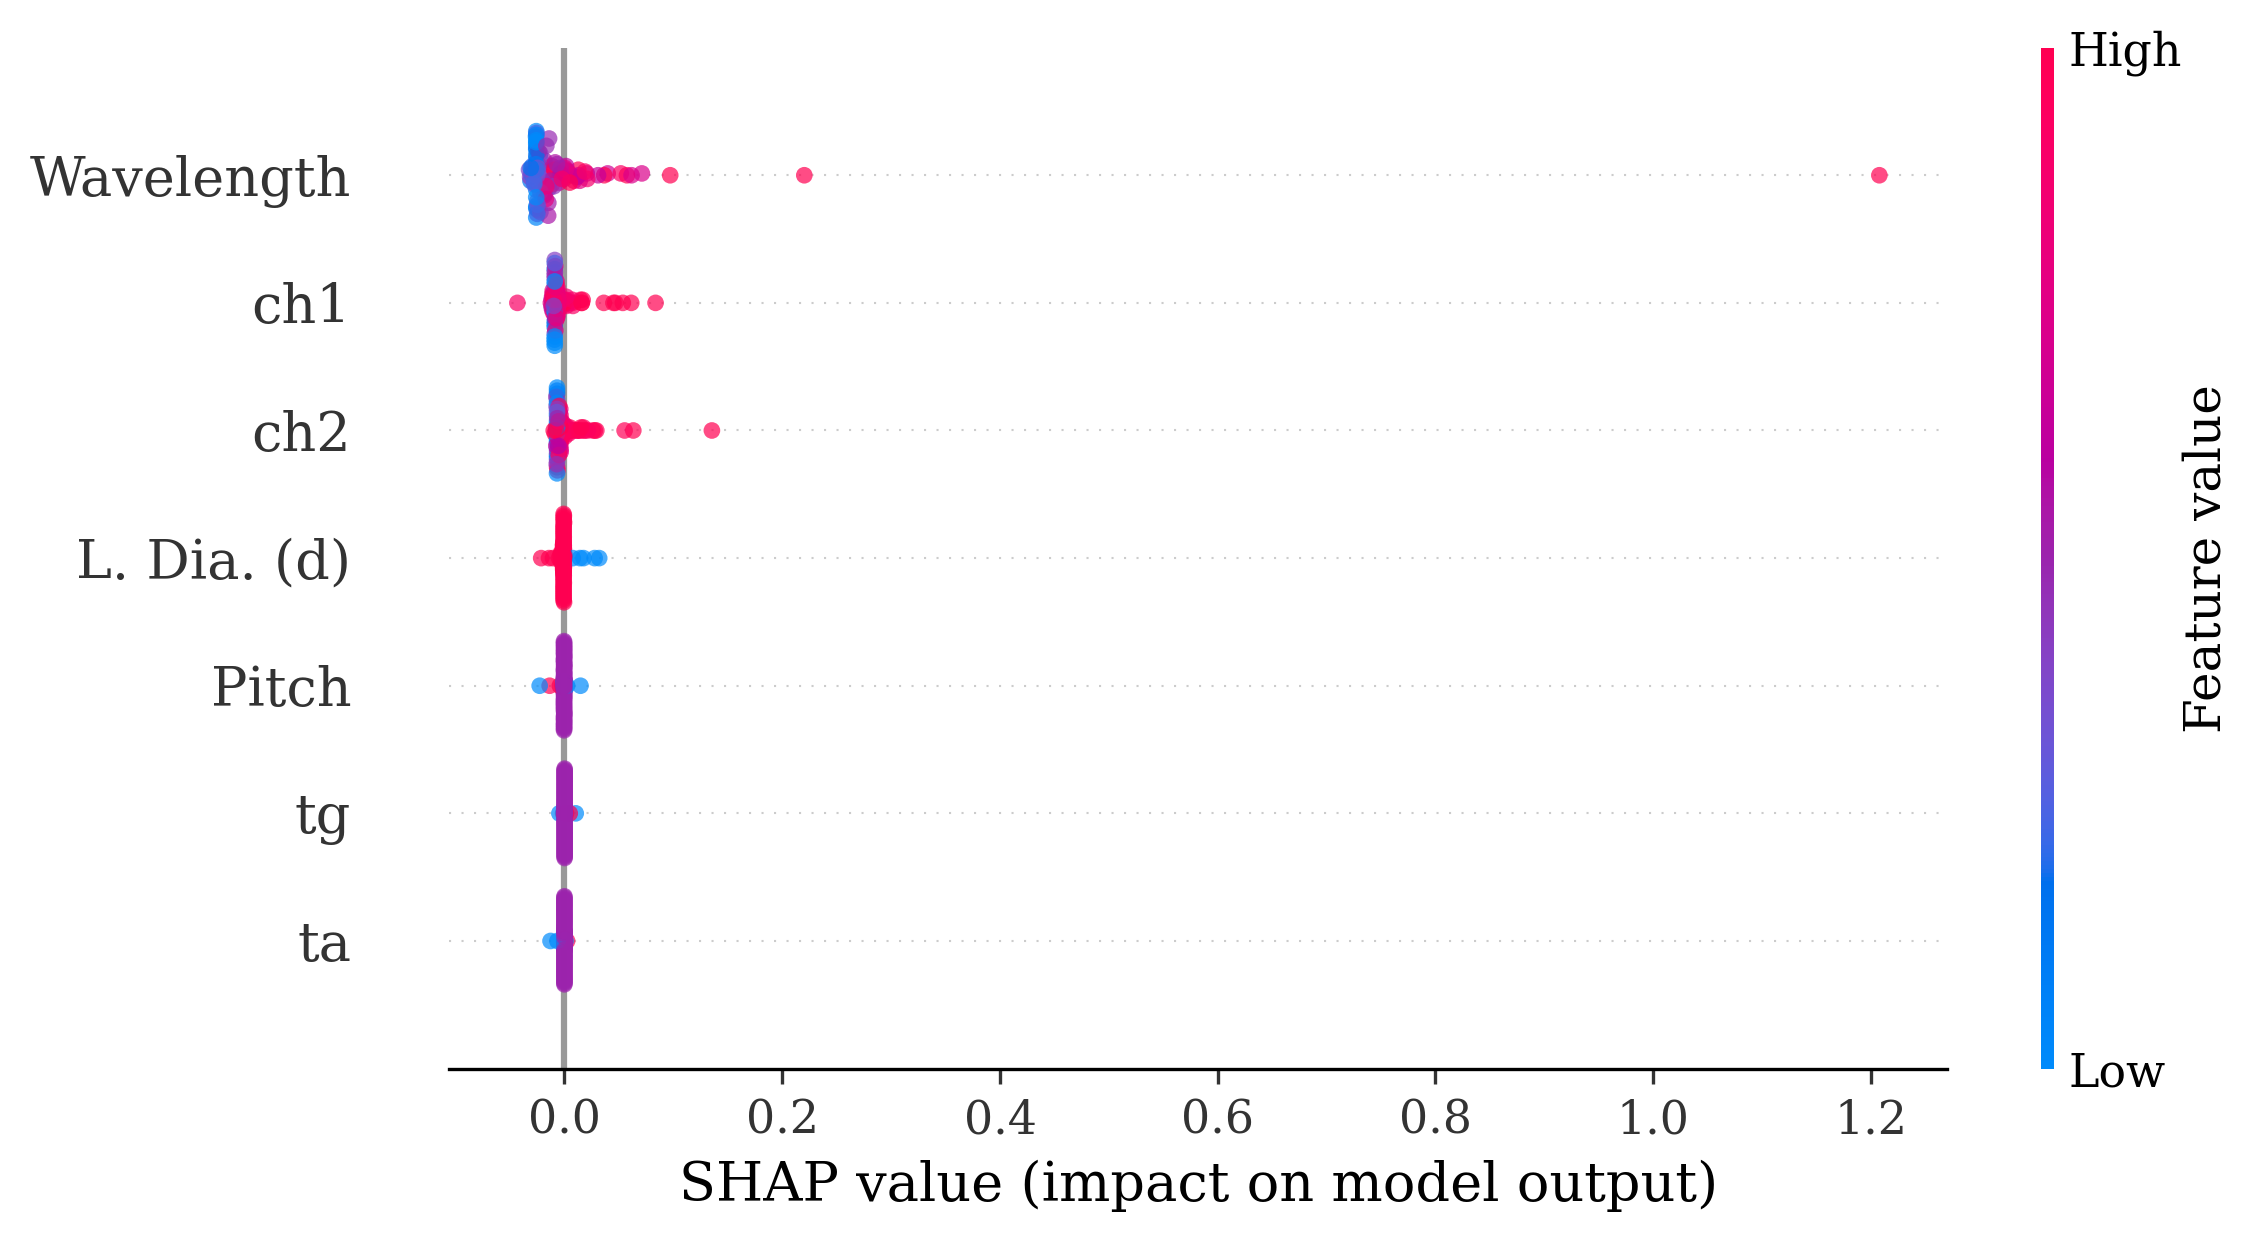

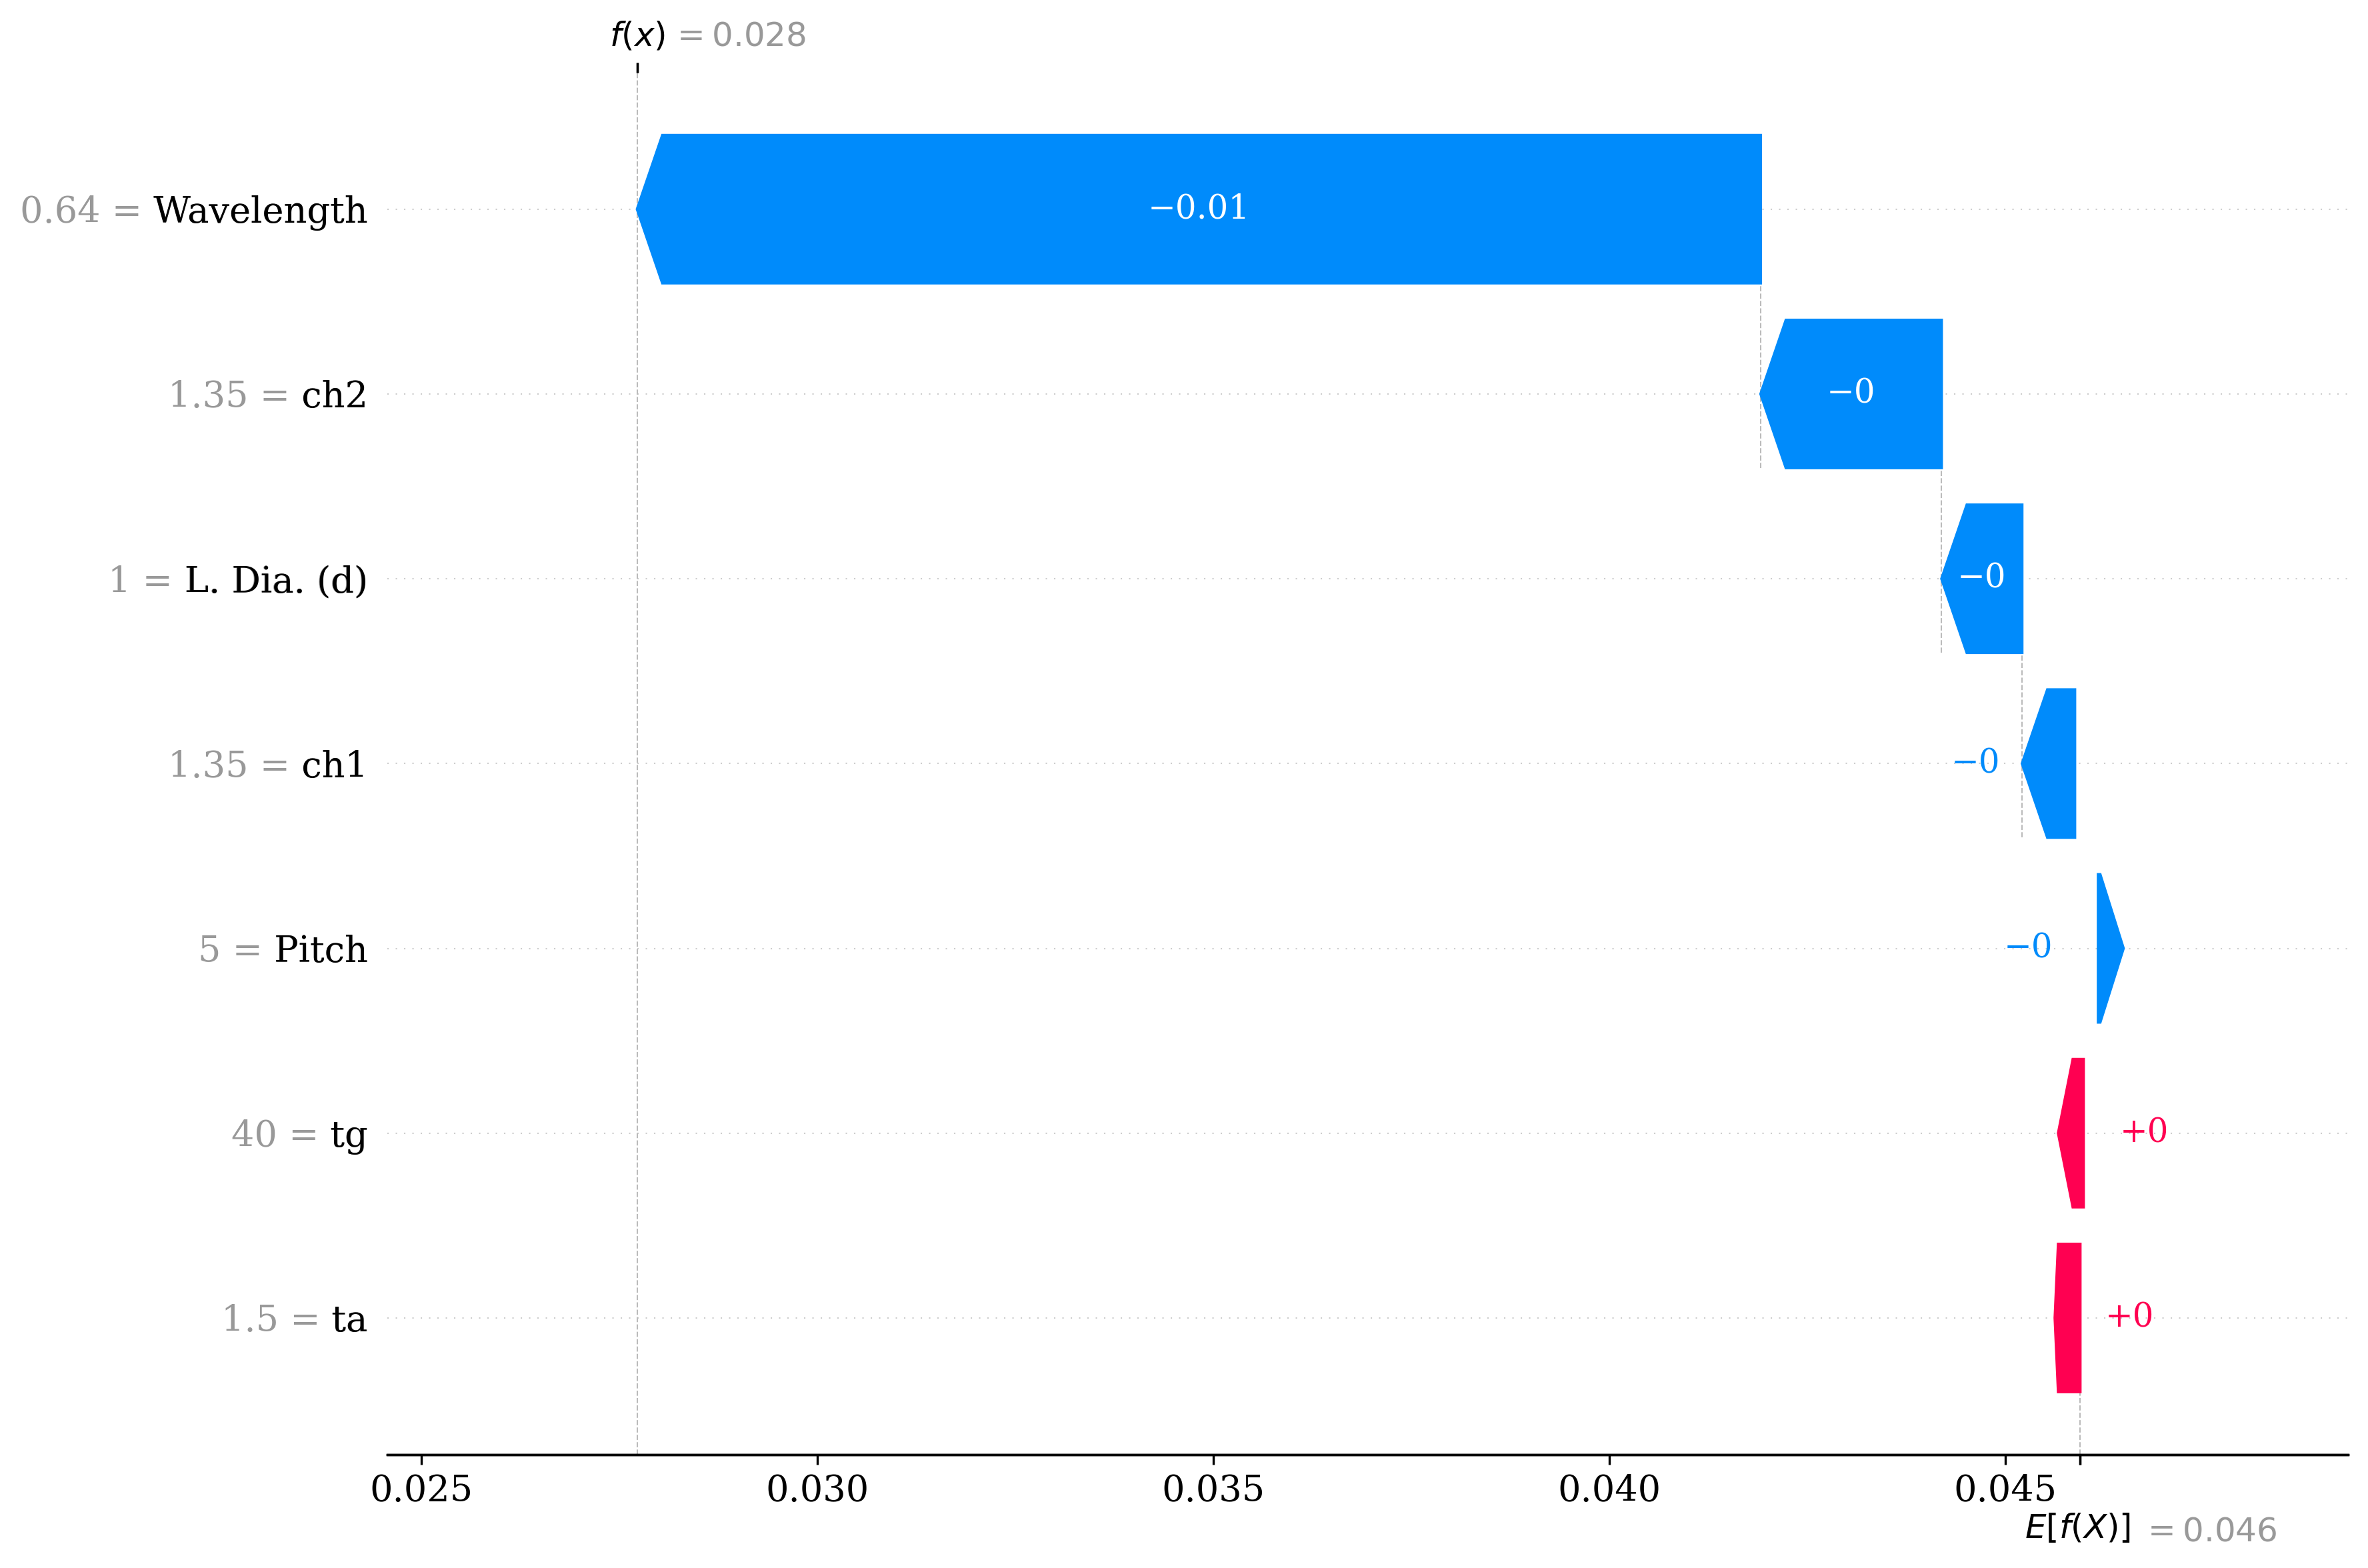


📊 Feature Ranking (based on mean |SHAP value|):
       Feature  Mean_SHAP
6   Wavelength   0.035527
4          ch1   0.011027
5          ch2   0.009180
1  L. Dia. (d)   0.002497
0        Pitch   0.000949
2           tg   0.000391
3           ta   0.000290


In [120]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- হাই-রেজল্যুশনের জন্য সেটিং ----------
plt.rcParams['figure.dpi'] = 300          # 300 DPI তে রেন্ডার করবে
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 12            # ফন্ট সাইজ বাড়ানো

# ব্যাকগ্রাউন্ড ও এক্সপ্লেইনার (আপনার আগের কোড)
background = X_train.sample(n=100, random_state=42)
explainer = shap.KernelExplainer(ensemble.predict, background)

X_test_sample = X_test.iloc[:100]
shap_values = explainer.shap_values(X_test_sample)

# ---------- 1. ব্যার চার্ট (ফিচার ইমপোর্ট্যান্স) - জুম ও ডিটেইল সহ ----------
plt.figure(figsize=(12, 8))   # বড় সাইজ
shap.summary_plot(shap_values, X_test_sample, feature_names=X.columns,
                  plot_type="bar", show=False, max_display=10)  # max_display কন্ট্রোল করে কয়টা ফিচার দেখাবে

plt.tight_layout()
plt.show()

# ---------- 2. ডট প্লট (বিস্তারিত প্রভাব) - জুম ও স্বচ্ছতা বাড়ানো ----------
# বড় ফিগার তৈরি
plt.figure(figsize=(14, 10))
shap.summary_plot(shap_values, X_test_sample, feature_names=X.columns,
                  show=False, max_display=10, alpha=0.7)  # alpha কমিয়ে ডটের ওভারল্যাপ কমানো যায়

# যদি কোনো নির্দিষ্ট অংশে জুম করতে চান (যেমন SHAP মানের রেঞ্জ -0.1 থেকে 0.1):
# plt.xlim(-0.1, 0.1)
plt.tight_layout()
plt.show()

# ---------- 3. ওয়াটারফল প্লট (প্রথম টেস্ট নমুনার জন্য) - আরও বড় ও শার্প ----------
# প্রথম নমুনার SHAP ব্যাখ্যা
explanation = shap.Explanation(values=shap_values[0],
                               base_values=explainer.expected_value,
                               data=X_test_sample.iloc[0].values,
                               feature_names=X.columns)

# ওয়াটারফল প্লটের সাইজ কাস্টমাইজ
shap.waterfall_plot(explanation, max_display=10, show=False)
plt.gcf().set_size_inches(12, 8)   # ফিগার সাইজ বাড়ানো
plt.tight_layout()
plt.show()

# ---------- 4. ফিচার র‌্যাঙ্কিং প্রিন্ট ----------
mean_abs_shap = np.abs(shap_values).mean(axis=0)
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Mean_SHAP': mean_abs_shap
}).sort_values('Mean_SHAP', ascending=False)

print("\n📊 Feature Ranking (based on mean |SHAP value|):")
print(feature_importance_df)

In [114]:
# 6. Save the final model
# ==============================
with open('final_model.pkl', 'wb') as f:
    pickle.dump(ensemble, f)
print("Model saved as 'final_model.pkl'")


Model saved as 'final_model.pkl'


Predictions saved to 'predictions.csv'.


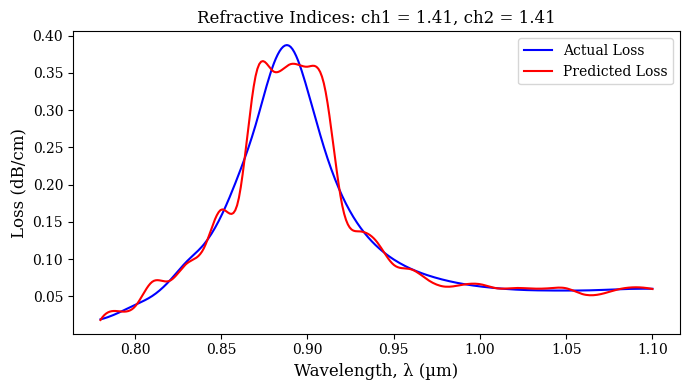

In [112]:
import pandas as pd
import numpy as npn
import matplotlib.pyplot as plt
import pickle
from scipy.interpolate import make_interp_spline




# --- Load the new data ---
new_data = pd.read_excel('/content/new_data.xlsx')

# --- Prepare features (X) and actual target (y_true) ---
X_new = new_data.drop('Loss', axis=1)
y_true = new_data['Loss']

# --- Predict ---
y_pred = ensemble.predict(X_new)

# --- Save predictions ---
new_data['Predicted Loss'] = y_pred
new_data.to_csv('predictions.csv', index=False)
print("Predictions saved to 'predictions.csv'.")

# --- Extract refractive index values for labeling ---
# Since all rows have the same ch1 and ch2, take the first row's values
ch1_val = X_new['ch1'].iloc[0]
ch2_val = X_new['ch2'].iloc[0]
# If the data contains multiple distinct pairs, you may want to group them
# For now, we'll just use the first pair.

# --- Visualization: Actual vs Predicted vs Wavelength ---
plt.rcParams["figure.figsize"] = [7, 4]
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({'font.family': 'serif'})

wavelengths = X_new['Wavelength'].values

# Sort by wavelength for smooth line
idx = np.argsort(wavelengths)
wavelengths_sorted = wavelengths[idx]
y_true_sorted = y_true.iloc[idx]
y_pred_sorted = y_pred[idx]

# Smoothing (optional – works well with many points)
if len(wavelengths_sorted) > 3:
    x_smooth = np.linspace(wavelengths_sorted.min(), wavelengths_sorted.max(), 300)
    spline_true = make_interp_spline(wavelengths_sorted, y_true_sorted, k=3)
    spline_pred = make_interp_spline(wavelengths_sorted, y_pred_sorted, k=3)
    y_true_smooth = spline_true(x_smooth)
    y_pred_smooth = spline_pred(x_smooth)

    plt.plot(x_smooth, y_true_smooth, linestyle='-', color='b', label='Actual Loss')
    plt.plot(x_smooth, y_pred_smooth, linestyle='-', color='r', label='Predicted Loss')
else:
    plt.plot(wavelengths_sorted, y_true_sorted, 'bo-', label='Actual Loss')
    plt.plot(wavelengths_sorted, y_pred_sorted, 'ro-', label='Predicted Loss')

plt.xlabel('Wavelength, λ (µm)', fontsize=12)
plt.ylabel('Loss (dB/cm)', fontsize=12)
plt.title(f'Refractive Indices: ch1 = {ch1_val}, ch2 = {ch2_val}', fontsize=12)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('comparison_plot.png', dpi=300)
plt.show()

Predictions saved to 'predictions2.csv'.


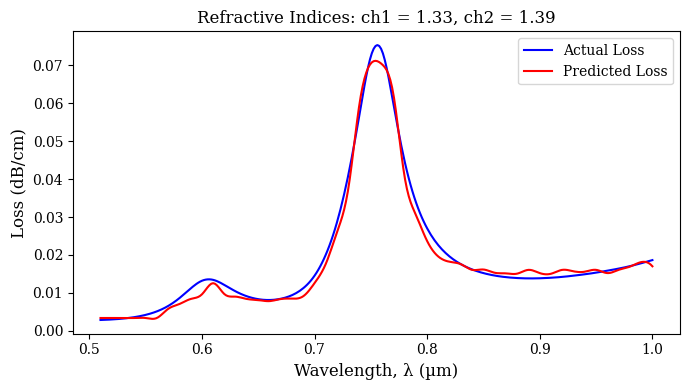

In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from scipy.interpolate import make_interp_spline


# --- Load the new data ---
new_data = pd.read_excel('/content/new_data2.xlsx')

# --- Prepare features (X) and actual target (y_true) ---
X_new = new_data.drop('Loss', axis=1)
y_true = new_data['Loss']

# --- Predict ---
y_pred = ensemble.predict(X_new)

# --- Save predictions ---
new_data['Predicted Loss'] = y_pred
new_data.to_csv('predictions1.csv', index=False)
print("Predictions saved to 'predictions2.csv'.")

# --- Extract refractive index values for labeling ---
# Since all rows have the same ch1 and ch2, take the first row's values
ch1_val = X_new['ch1'].iloc[0]
ch2_val = X_new['ch2'].iloc[0]
# If the data contains multiple distinct pairs, you may want to group them
# For now, we'll just use the first pair.

# --- Visualization: Actual vs Predicted vs Wavelength ---
plt.rcParams["figure.figsize"] = [7, 4]
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({'font.family': 'serif'})

wavelengths = X_new['Wavelength'].values

# Sort by wavelength for smooth line
idx = np.argsort(wavelengths)
wavelengths_sorted = wavelengths[idx]
y_true_sorted = y_true.iloc[idx]
y_pred_sorted = y_pred[idx]

# Smoothing (optional – works well with many points)
if len(wavelengths_sorted) > 3:
    x_smooth = np.linspace(wavelengths_sorted.min(), wavelengths_sorted.max(), 300)
    spline_true = make_interp_spline(wavelengths_sorted, y_true_sorted, k=3)
    spline_pred = make_interp_spline(wavelengths_sorted, y_pred_sorted, k=3)
    y_true_smooth = spline_true(x_smooth)
    y_pred_smooth = spline_pred(x_smooth)

    plt.plot(x_smooth, y_true_smooth, linestyle='-', color='b', label='Actual Loss')
    plt.plot(x_smooth, y_pred_smooth, linestyle='-', color='r', label='Predicted Loss')
else:
    plt.plot(wavelengths_sorted, y_true_sorted, 'bo-', label='Actual Loss')
    plt.plot(wavelengths_sorted, y_pred_sorted, 'ro-', label='Predicted Loss')

plt.xlabel('Wavelength, λ (µm)', fontsize=12)
plt.ylabel('Loss (dB/cm)', fontsize=12)
plt.title(f'Refractive Indices: ch1 = {ch1_val}, ch2 = {ch2_val}', fontsize=12)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('comparison_plot.png', dpi=300)
plt.show()

Predictions saved to 'predictions3.csv'.


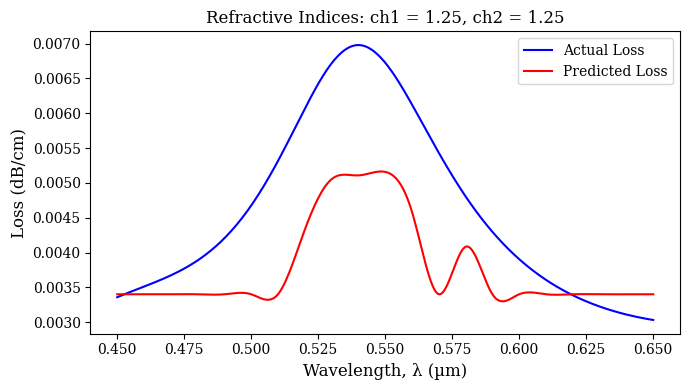

In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from scipy.interpolate import make_interp_spline


# --- Load the new data ---
new_data = pd.read_excel('/content/new_data3.xlsx')

# --- Prepare features (X) and actual target (y_true) ---
X_new = new_data.drop('Loss', axis=1)
y_true = new_data['Loss']

# --- Predict ---
y_pred = ensemble.predict(X_new)

# --- Save predictions ---
new_data['Predicted Loss'] = y_pred
new_data.to_csv('predictions1.csv', index=False)
print("Predictions saved to 'predictions3.csv'.")

# --- Extract refractive index values for labeling ---
# Since all rows have the same ch1 and ch2, take the first row's values
ch1_val = X_new['ch1'].iloc[0]
ch2_val = X_new['ch2'].iloc[0]
# If the data contains multiple distinct pairs, you may want to group them
# For now, we'll just use the first pair.

# --- Visualization: Actual vs Predicted vs Wavelength ---
plt.rcParams["figure.figsize"] = [7, 4]
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({'font.family': 'serif'})

wavelengths = X_new['Wavelength'].values

# Sort by wavelength for smooth line
idx = np.argsort(wavelengths)
wavelengths_sorted = wavelengths[idx]
y_true_sorted = y_true.iloc[idx]
y_pred_sorted = y_pred[idx]

# Smoothing (optional – works well with many points)
if len(wavelengths_sorted) > 3:
    x_smooth = np.linspace(wavelengths_sorted.min(), wavelengths_sorted.max(), 300)
    spline_true = make_interp_spline(wavelengths_sorted, y_true_sorted, k=3)
    spline_pred = make_interp_spline(wavelengths_sorted, y_pred_sorted, k=3)
    y_true_smooth = spline_true(x_smooth)
    y_pred_smooth = spline_pred(x_smooth)

    plt.plot(x_smooth, y_true_smooth, linestyle='-', color='b', label='Actual Loss')
    plt.plot(x_smooth, y_pred_smooth, linestyle='-', color='r', label='Predicted Loss')
else:
    plt.plot(wavelengths_sorted, y_true_sorted, 'bo-', label='Actual Loss')
    plt.plot(wavelengths_sorted, y_pred_sorted, 'ro-', label='Predicted Loss')

plt.xlabel('Wavelength, λ (µm)', fontsize=12)
plt.ylabel('Loss (dB/cm)', fontsize=12)
plt.title(f'Refractive Indices: ch1 = {ch1_val}, ch2 = {ch2_val}', fontsize=12)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('comparison_plot.png', dpi=300)
plt.show()

Predictions saved to 'predictions4.csv'.


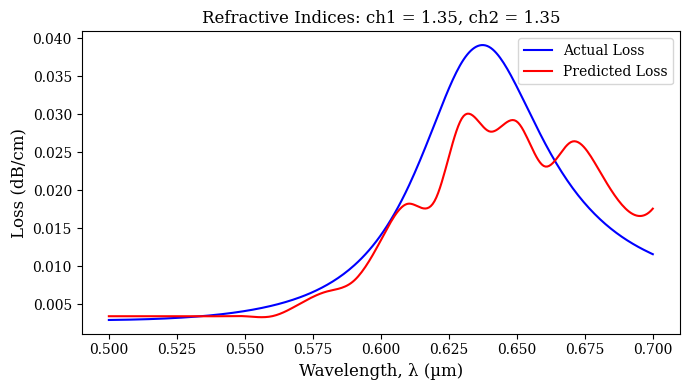

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from scipy.interpolate import make_interp_spline


# --- Load the new data ---
new_data = pd.read_excel('/content/new_data4.xlsx')

# --- Prepare features (X) and actual target (y_true) ---
X_new = new_data.drop('Loss', axis=1)
y_true = new_data['Loss']

# --- Predict ---
y_pred = ensemble.predict(X_new)

# --- Save predictions ---
new_data['Predicted Loss'] = y_pred
new_data.to_csv('predictions3.csv', index=False)
print("Predictions saved to 'predictions4.csv'.")

# --- Extract refractive index values for labeling ---
# Since all rows have the same ch1 and ch2, take the first row's values
ch1_val = X_new['ch1'].iloc[0]
ch2_val = X_new['ch2'].iloc[0]
# If the data contains multiple distinct pairs, you may want to group them
# For now, we'll just use the first pair.

# --- Visualization: Actual vs Predicted vs Wavelength ---
plt.rcParams["figure.figsize"] = [7, 4]
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({'font.family': 'serif'})

wavelengths = X_new['Wavelength'].values

# Sort by wavelength for smooth line
idx = np.argsort(wavelengths)
wavelengths_sorted = wavelengths[idx]
y_true_sorted = y_true.iloc[idx]
y_pred_sorted = y_pred[idx]

# Smoothing (optional – works well with many points)
if len(wavelengths_sorted) > 3:
    x_smooth = np.linspace(wavelengths_sorted.min(), wavelengths_sorted.max(), 300)
    spline_true = make_interp_spline(wavelengths_sorted, y_true_sorted, k=3)
    spline_pred = make_interp_spline(wavelengths_sorted, y_pred_sorted, k=3)
    y_true_smooth = spline_true(x_smooth)
    y_pred_smooth = spline_pred(x_smooth)

    plt.plot(x_smooth, y_true_smooth, linestyle='-', color='b', label='Actual Loss')
    plt.plot(x_smooth, y_pred_smooth, linestyle='-', color='r', label='Predicted Loss')
else:
    plt.plot(wavelengths_sorted, y_true_sorted, 'bo-', label='Actual Loss')
    plt.plot(wavelengths_sorted, y_pred_sorted, 'ro-', label='Predicted Loss')

plt.xlabel('Wavelength, λ (µm)', fontsize=12)
plt.ylabel('Loss (dB/cm)', fontsize=12)
plt.title(f'Refractive Indices: ch1 = {ch1_val}, ch2 = {ch2_val}', fontsize=12)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('comparison_plot.png', dpi=300)
plt.show()

Predictions saved to 'predictions5.csv'.


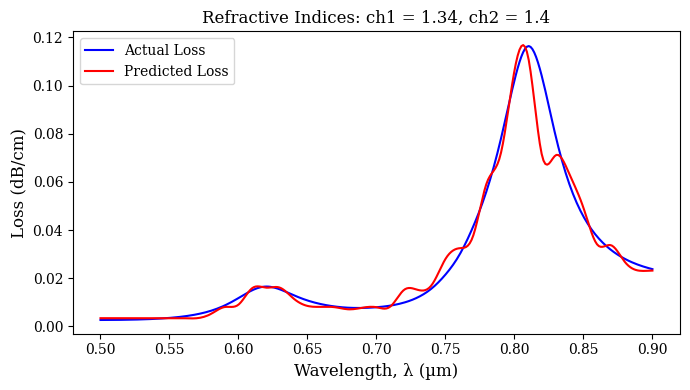

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from scipy.interpolate import make_interp_spline


# --- Load the new data ---
new_data = pd.read_excel('/content/new_data5.xlsx')



# --- Prepare features (X) and actual target (y_true) ---
X_new = new_data.drop('Loss', axis=1)
y_true = new_data['Loss']

# --- Predict ---
y_pred = ensemble.predict(X_new)

# --- Save predictions ---
new_data['Predicted Loss'] = y_pred
new_data.to_csv('predictions5.csv', index=False)
print("Predictions saved to 'predictions5.csv'.")

# --- Extract refractive index values for labeling ---
# Since all rows have the same ch1 and ch2, take the first row's values
ch1_val = X_new['ch1'].iloc[0]
ch2_val = X_new['ch2'].iloc[0]
# If the data contains multiple distinct pairs, you may want to group them
# For now, we'll just use the first pair.

# --- Visualization: Actual vs Predicted vs Wavelength ---
plt.rcParams["figure.figsize"] = [7, 4]
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({'font.family': 'serif'})

wavelengths = X_new['Wavelength'].values

# Sort by wavelength for smooth line
idx = np.argsort(wavelengths)
wavelengths_sorted = wavelengths[idx]
y_true_sorted = y_true.iloc[idx]
y_pred_sorted = y_pred[idx]

# Smoothing (optional – works well with many points)
if len(wavelengths_sorted) > 3:
    x_smooth = np.linspace(wavelengths_sorted.min(), wavelengths_sorted.max(), 300)
    spline_true = make_interp_spline(wavelengths_sorted, y_true_sorted, k=3)
    spline_pred = make_interp_spline(wavelengths_sorted, y_pred_sorted, k=3)
    y_true_smooth = spline_true(x_smooth)
    y_pred_smooth = spline_pred(x_smooth)

    plt.plot(x_smooth, y_true_smooth, linestyle='-', color='b', label='Actual Loss')
    plt.plot(x_smooth, y_pred_smooth, linestyle='-', color='r', label='Predicted Loss')
else:
    plt.plot(wavelengths_sorted, y_true_sorted, 'bo-', label='Actual Loss')
    plt.plot(wavelengths_sorted, y_pred_sorted, 'ro-', label='Predicted Loss')

plt.xlabel('Wavelength, λ (µm)', fontsize=12)
plt.ylabel('Loss (dB/cm)', fontsize=12)
plt.title(f'Refractive Indices: ch1 = {ch1_val}, ch2 = {ch2_val}', fontsize=12)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('comparison_plot.png', dpi=300)
plt.show()

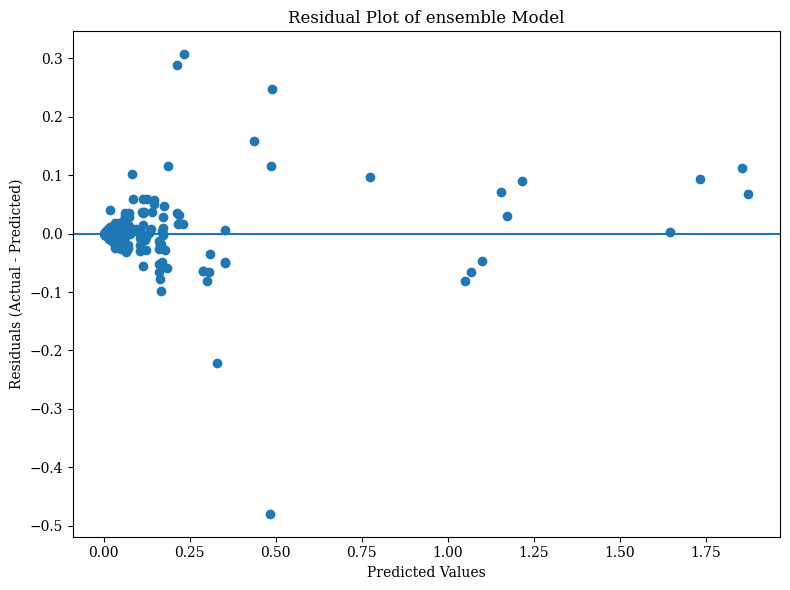

In [110]:
import numpy as np
import matplotlib.pyplot as plt

# ============================
# Assuming you already have:
# rf_model (trained Random Forest model)
# X_test, y_test
# ============================

# Prediction
y_pred = ensemble.predict(X_test)

# Residual calculation
residuals = y_test - y_pred

# ============================
# Plot
# ============================
plt.figure(figsize=(8,6))

plt.scatter(y_pred, residuals)
plt.axhline(y=0)

# Labels and title
plt.xlabel("Predicted Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot of ensemble Model")

plt.tight_layout()
plt.show()

Predictions saved to 'predictions5.csv'.


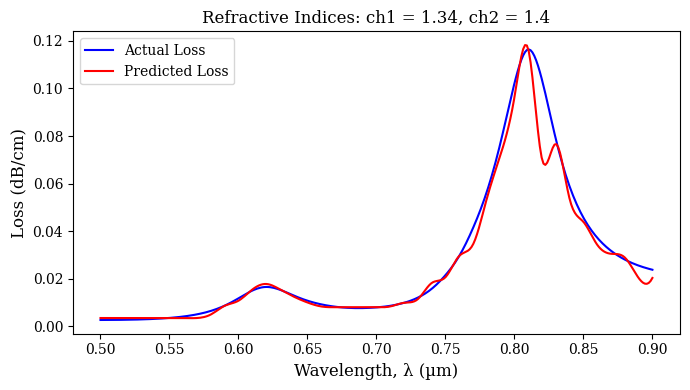

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from scipy.interpolate import make_interp_spline


# --- Load the new data ---
new_data = pd.read_excel('/content/new_data5.xlsx')



# --- Prepare features (X) and actual target (y_true) ---
X_new = new_data.drop('Loss', axis=1)
y_true = new_data['Loss']

# --- Predict ---
y_pred = ensemble.predict(X_new)

# --- Save predictions ---
new_data['Predicted Loss'] = y_pred
new_data.to_csv('predictions5.csv', index=False)
print("Predictions saved to 'predictions5.csv'.")

# --- Extract refractive index values for labeling ---
# Since all rows have the same ch1 and ch2, take the first row's values
ch1_val = X_new['ch1'].iloc[0]
ch2_val = X_new['ch2'].iloc[0]
# If the data contains multiple distinct pairs, you may want to group them
# For now, we'll just use the first pair.

# --- Visualization: Actual vs Predicted vs Wavelength ---
plt.rcParams["figure.figsize"] = [7, 4]
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({'font.family': 'serif'})

wavelengths = X_new['Wavelength'].values

# Sort by wavelength for smooth line
idx = np.argsort(wavelengths)
wavelengths_sorted = wavelengths[idx]
y_true_sorted = y_true.iloc[idx]
y_pred_sorted = y_pred[idx]

# Smoothing (optional – works well with many points)
if len(wavelengths_sorted) > 3:
    x_smooth = np.linspace(wavelengths_sorted.min(), wavelengths_sorted.max(), 300)
    spline_true = make_interp_spline(wavelengths_sorted, y_true_sorted, k=3)
    spline_pred = make_interp_spline(wavelengths_sorted, y_pred_sorted, k=3)
    y_true_smooth = spline_true(x_smooth)
    y_pred_smooth = spline_pred(x_smooth)

    plt.plot(x_smooth, y_true_smooth, linestyle='-', color='b', label='Actual Loss')
    plt.plot(x_smooth, y_pred_smooth, linestyle='-', color='r', label='Predicted Loss')
else:
    plt.plot(wavelengths_sorted, y_true_sorted, 'bo-', label='Actual Loss')
    plt.plot(wavelengths_sorted, y_pred_sorted, 'ro-', label='Predicted Loss')

plt.xlabel('Wavelength, λ (µm)', fontsize=12)
plt.ylabel('Loss (dB/cm)', fontsize=12)
plt.title(f'Refractive Indices: ch1 = {ch1_val}, ch2 = {ch2_val}', fontsize=12)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('comparison_plot.png', dpi=300)
plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Train prediction
y_train_pred = rf_model.predict(X_train)

# Test prediction
y_test_pred = rf_model.predict(X_test)

# Metrics (Train)
train_mse = mean_squared_error(y_train, y_train_pred)
train_mae = mean_absolute_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Metrics (Test)
test_mse = mean_squared_error(y_test, y_test_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("TRAIN:")
print(train_mse, train_mae, train_r2)

print("\nTEST:")
print(test_mse, test_mae, test_r2)

TRAIN:
0.000547099326546714 0.005565073092303288 0.9925159299439622

TEST:
0.0017344457617859148 0.01204653232474247 0.9572268369919678


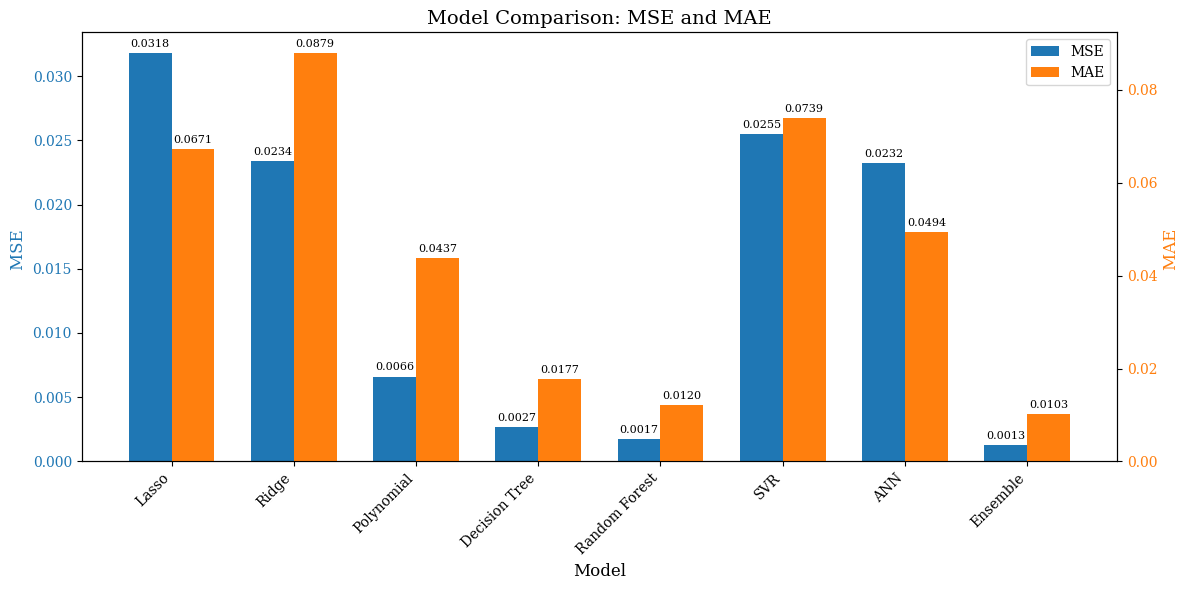

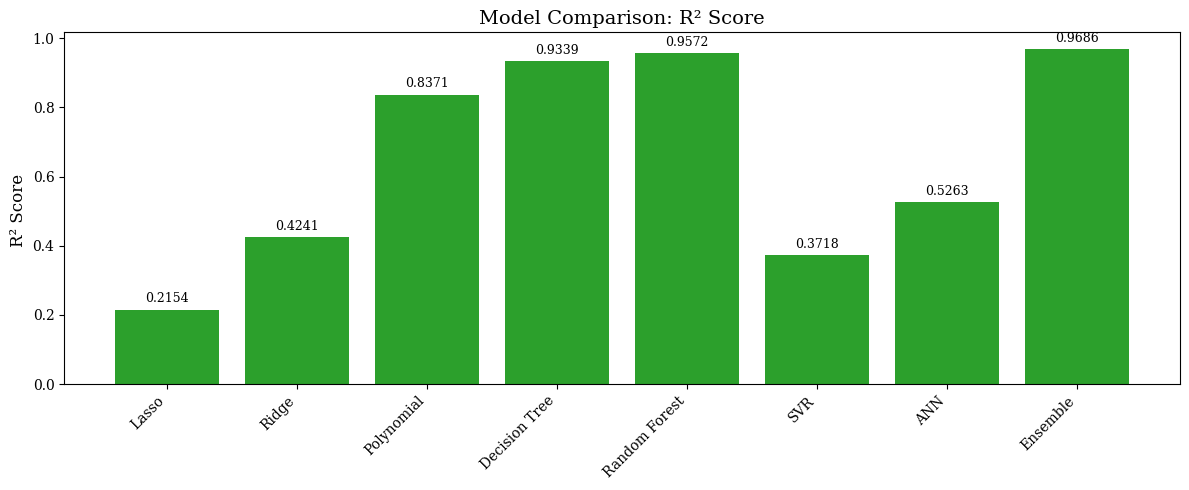

In [109]:
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------
# 1. ডেটা (আপনার দেওয়া ক্রম অনুযায়ী)
# --------------------------------
models = ['Lasso', 'Ridge', 'Polynomial', 'Decision Tree', 'Random Forest', 'SVR', 'ANN', 'Ensemble']

mse = [
    0.031814437654487875,   # Lasso
    0.023354615844381935,   # Ridge
    0.006607433941228954,   # Polynomial
    0.002682247688204441,   # Decision Tree
    0.0017344457617859148,  # Random Forest
    0.02547291356018838,    # SVR
    0.023241,               # ANN
    0.001275127526932449    # Ensemble
]

mae = [
    0.06714500620262408,    # Lasso
    0.0879336536496915,     # Ridge
    0.0437265613234689,     # Polynomial
    0.017731914925555738,   # Decision Tree
    0.01204653232474247,    # Random Forest
    0.07388134869182618,    # SVR
    0.049396,               # ANN
    0.010254840622188654    # Ensemble
]

r2 = [
    0.2154242249679208,     # Lasso
    0.42405187149056356,    # Ridge
    0.8370540865215736,     # Polynomial
    0.9338530958285178,     # Decision Tree
    0.9572268369919678,     # Random Forest
    0.37181253631271605,    # SVR
    0.526297,               # ANN
    0.968554082942697       # Ensemble
]

# --------------------------------
# 2. প্লট ১: MSE ও MAE (ডুয়াল অক্ষ)
# --------------------------------
x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(12, 6))

# MSE (নীল) – বাম অক্ষ
bars1 = ax1.bar(x - width/2, mse, width, label='MSE', color='#1f77b4')
ax1.set_xlabel('Model', fontsize=12)
ax1.set_ylabel('MSE ', color='#1f77b4', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#1f77b4')
ax1.set_xticks(x)
ax1.set_xticklabels(models, rotation=45, ha='right')

# MAE (কমলা) – ডান অক্ষ
ax2 = ax1.twinx()
bars2 = ax2.bar(x + width/2, mae, width, label='MAE', color='#ff7f0e')
ax2.set_ylabel('MAE ', color='#ff7f0e', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#ff7f0e')

# লেজেন্ড একত্রিত করতে
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

# বারগুলোর মান লেখা
def autolabel(bars, ax):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

autolabel(bars1, ax1)
autolabel(bars2, ax2)

plt.title('Model Comparison: MSE and MAE', fontsize=14)
plt.tight_layout()
plt.show()

# --------------------------------
# 3. প্লট ২: R² (উচ্চতর ভালো)
# --------------------------------
plt.figure(figsize=(12, 5))
bars3 = plt.bar(models, r2, color='#2ca02c')
plt.ylabel('R² Score ', fontsize=12)
plt.title('Model Comparison: R² Score', fontsize=14)
plt.xticks(rotation=45, ha='right')
for bar in bars3:
    height = bar.get_height()
    plt.annotate(f'{height:.4f}',
                 xy=(bar.get_x() + bar.get_width()/2, height),
                 xytext=(0, 3),
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()